# Lecture 19

Today's Topics:

- From Denoising to Generating
- The Forward Process: Adding Noise
- Training: Predicting the Noise
- A Small U-Net
- Sampling: From Static to Clothing
- Asking for Something Specific: Classifier-Free Guidance
- Stable Diffusion: VAE + U-Net + Text Encoder
- Experiments with Stable Diffusion
- Responsible Use

> **Run this notebook on a GPU.** In Google Colab: *Runtime → Change runtime type → T4 GPU*. Part 1 trains a small model (a few minutes on a GPU), and Part 2 runs Stable Diffusion, which is impractical on a CPU.

In [2]:
import copy
import math
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import torchvision
from torchvision import datasets, transforms

print(f"PyTorch version: {torch.__version__}\ntorchvision version: {torchvision.__version__}")

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

TRAIN = False   # set to False to load pretrained weights instead of training (useful on a CPU)

PyTorch version: 2.15.0+cu132
torchvision version: 0.29.2+cu132
Device: cpu


# Part 1: Diffusion from Scratch

## From Denoising to Generating

At the end of last lecture, a denoising autoencoder took a very noisy image and produced a plausible clean piece of clothing. It wasn't recovering the exact original; it was making its best guess at "what clothing could be under this noise".

So here's a strange idea: what if we give a denoiser an image that is **pure noise**, with no clothing under it at all? Its best guess would be *some* plausible piece of clothing: a brand-new image.

A single jump from pure static to a clean image is too hard to do well; that's partly why VAE samples were blurry. **Diffusion models** split the job into many small steps. Each step removes just a little noise, and each small step is an easy problem. Chain a few dozen of them together and an image emerges from static.

This is the idea behind Stable Diffusion, DALL·E, Midjourney and most modern image generators. We'll build a small version on FashionMNIST in Part 1, then open up Stable Diffusion in Part 2.

We scale pixels to $[-1, 1]$ instead of $[0, 1]$, so that the images are centered at 0, just like the random noise we'll be mixing them with.

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),                 # [0, 1]
    transforms.Normalize([0.5], [0.5]),    # [-1, 1]
])
train_data = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
class_names = train_data.classes

BATCH_SIZE = 128
train_dataloader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)


def show_images(images, n_cols=10, title="", row_labels=None, size=1.0):
    # Displays a batch of images with values in [-1, 1]
    images = images.detach().cpu().clamp(-1, 1)
    n_rows = math.ceil(len(images) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * size, n_rows * size * 1.05), squeeze=False)
    for ax in axes.flat:
        ax.axis(False)
    for ax, img in zip(axes.flat, images):
        ax.imshow(img.squeeze(), cmap="gray", vmin=-1, vmax=1)
    if row_labels:
        for r, label in enumerate(row_labels):
            axes[r, 0].axis(True)
            axes[r, 0].set_xticks([])
            axes[r, 0].set_yticks([])
            for spine in axes[r, 0].spines.values():
                spine.set_visible(False)
            axes[r, 0].set_ylabel(label, rotation=0, ha="right", va="center", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

100.0%
100.0%
100.0%
100.0%


## The Forward Process: Adding Noise

First the easy direction: destroying an image. We pick a number of steps, $T = 1000$, and at each step $t$ we shrink the image slightly and mix in a little Gaussian noise:

$$x_t = \sqrt{1 - \beta_t}\; x_{t-1} + \sqrt{\beta_t}\; \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 1)$$

The amounts $\beta_t$ are called the **noise schedule**. We use the standard choice from the original diffusion paper (Ho et al., 2020): $\beta_t$ grows in a straight line from $0.0001$ to $0.02$.

We don't actually have to add noise 1,000 times to get to step $t$. Because adding Gaussian noise to Gaussian noise gives Gaussian noise, all the steps combine into **one formula** that jumps straight from the clean image $x_0$ to any step $t$:

$$x_t = \sqrt{\bar\alpha_t}\; x_0 + \sqrt{1 - \bar\alpha_t}\; \varepsilon, \qquad \text{where } \bar\alpha_t = \prod_{s=1}^{t} (1 - \beta_s)$$

So $x_t$ is just a **weighted mix** of the clean image and pure noise. $\sqrt{\bar\alpha_t}$ is the weight on the image, and it shrinks from 1 to almost 0 as $t$ goes from 0 to 1000.

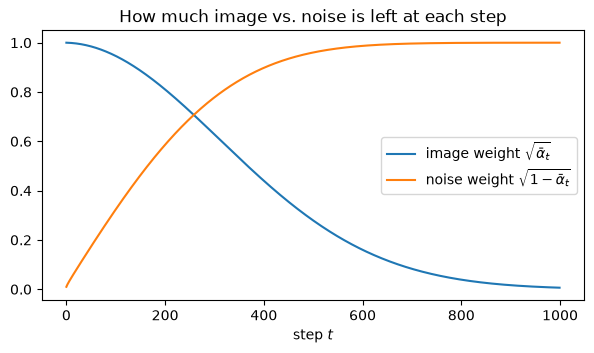

In [4]:
T = 1000
betas = torch.linspace(1e-4, 0.02, T).to(device)
alpha_bars = torch.cumprod(1 - betas, dim=0)


def add_noise(x0, t, noise):
    # Jump straight from clean images x0 to noise level t (one t per image)
    a = alpha_bars[t].view(-1, 1, 1, 1)
    return a.sqrt() * x0 + (1 - a).sqrt() * noise


plt.figure(figsize=(7, 3.5))
plt.plot(alpha_bars.sqrt().cpu(), label=r"image weight $\sqrt{\bar\alpha_t}$")
plt.plot((1 - alpha_bars).sqrt().cpu(), label=r"noise weight $\sqrt{1-\bar\alpha_t}$")
plt.xlabel("step $t$")
plt.title("How much image vs. noise is left at each step")
plt.legend()
plt.show()

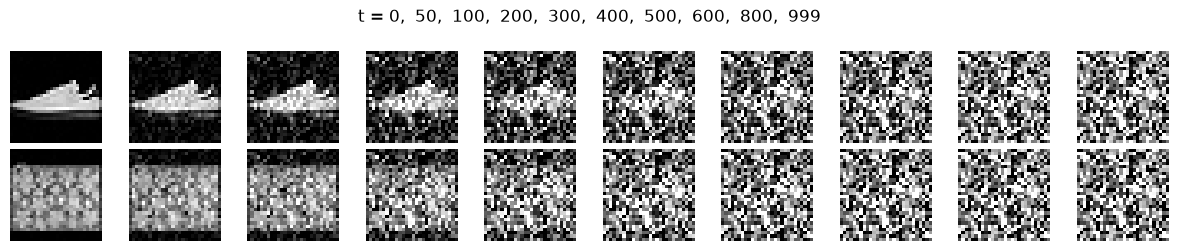

In [5]:
sneaker = next(train_data[i][0] for i in range(100) if train_data[i][1] == class_names.index("Sneaker"))
bag = next(train_data[i][0] for i in range(100) if train_data[i][1] == class_names.index("Bag"))

ts = [0, 50, 100, 200, 300, 400, 500, 600, 800, 999]
torch.manual_seed(0)
noise = torch.randn(1, 1, 28, 28).to(device)
strip = torch.cat([add_noise(img.unsqueeze(0).to(device), torch.tensor([t]).to(device), noise)
                   for img in (sneaker, bag) for t in ts])
show_images(strip, n_cols=len(ts), title="t = " + ",  ".join(map(str, ts)), size=1.2)

Try it yourself with the slider (it works in Jupyter and Colab). At what step can you no longer tell what the item is?

In [ ]:
try:
    from ipywidgets import interact, IntSlider

    def show_noise_level(t=0):
        x = add_noise(sneaker.unsqueeze(0).to(device), torch.tensor([t]).to(device), noise)
        plt.figure(figsize=(3, 3))
        plt.imshow(x.squeeze().cpu(), cmap="gray", vmin=-1, vmax=1)
        plt.title(f"t = {t}, image weight = {alpha_bars[t].sqrt():.2f}")
        plt.axis(False)
        plt.show()

    interact(show_noise_level, t=IntSlider(min=0, max=T - 1, step=10, value=0))
except ImportError:
    print("ipywidgets isn't installed; skip this cell or run: pip install ipywidgets")

By around $t = 400$-$500$ the item is gone to the eye, even though the image weight is still well above zero. The last few hundred steps turn "barely visible" into pure static. That's what the model has to learn to undo.

## Training: Predicting the Noise

Now the hard direction. We'll train a network that looks at a noisy image $x_t$ and predicts **the noise $\varepsilon$ that was added to it**. If we know the noise, we can subtract it and recover the clean image, by rearranging the formula above:

$$\hat{x}_0 = \frac{x_t - \sqrt{1 - \bar\alpha_t}\;\hat\varepsilon}{\sqrt{\bar\alpha_t}}$$

Training is surprisingly simple. For each batch:

1. Take clean images $x_0$.
2. Pick a random step $t$ for each image, and random noise $\varepsilon$.
3. Make the noisy images $x_t$ with `add_noise()`.
4. Ask the network to predict $\varepsilon$ from $x_t$.
5. Loss = **mean squared error** between the predicted and the true noise.

That's it: diffusion training is **regression**. The target is a 784-number noise image, and we already know the right answer because we added the noise ourselves. No labels needed, and no tricky loss like the VAE's KL term.

The network needs two extra inputs:

- **The step $t$**, so it knows how noisy the input is. A slightly noisy image needs a gentle correction; pure static needs a big one. We turn $t$ into a vector with sines and cosines of different frequencies, the same **sinusoidal encoding** the Transformer uses for word positions (from the Illustrated Transformer reading).
- **The class label** (optional), so that later we can ask for "a sneaker". We give it 11 possible labels: the 10 classes plus a special **"no label"** (label 10). During training we hide the real label 10% of the time, so the same network learns to generate both *with* and *without* a label. We'll need both for guidance later.

In [ ]:
NULL_LABEL = 10           # "no label"
LABEL_DROP_PROB = 0.1     # how often we hide the label during training


def diffusion_loss(model, x0, y):
    t = torch.randint(0, T, (len(x0),), device=x0.device)       # a random noise level per image
    noise = torch.randn_like(x0)                                 # the noise we'll add
    x_noisy = add_noise(x0, t, noise)
    hide = torch.rand(len(y), device=y.device) < LABEL_DROP_PROB
    y = torch.where(hide, torch.full_like(y, NULL_LABEL), y)     # sometimes, hide the label
    noise_pred = model(x_noisy, t, y)
    return F.mse_loss(noise_pred, noise)                         # regression on the noise

## A Small U-Net

The network takes an image and outputs an image of the same size (the predicted noise). The standard architecture for this is a **U-Net**:

- The **down path** shrinks the image ($28 \to 14 \to 7$ pixels) while adding channels, like the convolutional blocks of TinyVGG (Lecture 14). Small images with many channels capture *what* is in the picture.
- The **up path** grows it back ($7 \to 14 \to 28$).
- **Skip connections** pass each down-path layer straight across to the matching up-path layer, so the fine details (*where* the edges are) don't get lost in the bottleneck. This is the key difference from last lecture's autoencoder, which forced everything through a narrow code.

```
28x28 ──────────────────────────────▶ 28x28 ─▶ predicted noise
   ╲                                  ╱
   14x14 ─────────────────────▶ 14x14
      ╲                        ╱
       7x7 ───── middle ───── 7x7
```

Each block is a **residual block** like ResNet's (Lecture 17): two convolutions plus a shortcut that adds the input back. The time step and label are turned into one vector (`emb`) that's added inside every block, so every layer knows how noisy the input is and what was asked for. `nn.GroupNorm` and `F.silu` (a smooth version of ReLU) are standard choices in diffusion models.

In [ ]:
def timestep_embedding(t, dim):
    # Sinusoidal encoding of the step t (as in the Transformer's positional encoding)
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)


class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, emb_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, kernel_size=3, padding=1)
        self.emb = nn.Linear(emb_dim, c_out)         # injects the time step + label
        self.norm2 = nn.GroupNorm(8, c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, kernel_size=3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, kernel_size=1) if c_in != c_out else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb(emb)[:, :, None, None]      # same value added at every pixel
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)                      # residual connection


class UNet(nn.Module):
    def __init__(self, channels=(32, 64, 128), emb_dim=128, num_classes=10):
        super().__init__()
        c1, c2, c3 = channels
        self.emb_dim = emb_dim
        self.time_mlp = nn.Sequential(nn.Linear(emb_dim, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.class_emb = nn.Embedding(num_classes + 1, emb_dim)   # +1 for "no label"

        self.inp = nn.Conv2d(1, c1, kernel_size=3, padding=1)
        self.down1 = ResBlock(c1, c1, emb_dim)        # 28x28
        self.down2 = ResBlock(c1, c2, emb_dim)        # 14x14
        self.down3 = ResBlock(c2, c3, emb_dim)        # 7x7
        self.mid = ResBlock(c3, c3, emb_dim)          # 7x7
        self.up3 = ResBlock(c3 + c3, c2, emb_dim)     # 7x7   (input: middle + skip from down3)
        self.up2 = ResBlock(c2 + c2, c1, emb_dim)     # 14x14 (input: upsampled + skip from down2)
        self.up1 = ResBlock(c1 + c1, c1, emb_dim)     # 28x28 (input: upsampled + skip from down1)
        self.out = nn.Sequential(nn.GroupNorm(8, c1), nn.SiLU(), nn.Conv2d(c1, 1, kernel_size=3, padding=1))

    def forward(self, x, t, y):
        emb = self.time_mlp(timestep_embedding(t, self.emb_dim)) + self.class_emb(y)

        h1 = self.down1(self.inp(x), emb)                                       # 28x28
        h2 = self.down2(F.avg_pool2d(h1, 2), emb)                               # 14x14
        h3 = self.down3(F.avg_pool2d(h2, 2), emb)                               # 7x7

        h = self.mid(h3, emb)
        h = self.up3(torch.cat([h, h3], dim=1), emb)                            # 7x7
        h = self.up2(torch.cat([F.interpolate(h, scale_factor=2), h2], dim=1), emb)  # 14x14
        h = self.up1(torch.cat([F.interpolate(h, scale_factor=2), h1], dim=1), emb)  # 28x28
        return self.out(h)


torch.manual_seed(42)
model = UNet().to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

### Training

We train for a fixed number of optimizer steps (8,000 batches, about 17 passes through the data). On a Colab T4 GPU this takes a few minutes. Afterwards we save the weights, so you can reload them later without retraining.

One new trick: an **exponential moving average (EMA)** of the weights. Each training step nudges the weights based on one random batch, so they jitter from step to step, and a model saved at any single moment carries some of that jitter. We keep a second copy of the model whose weights are a running average: after every step, each EMA weight moves 0.1% of the way toward the current weight. It's the same idea as momentum (Lecture 16), applied to the weights themselves. We generate with the smoothed copy, which gives noticeably cleaner images. Nearly every diffusion model does this, Stable Diffusion included.

In [ ]:
TRAIN_STEPS = 8000
CHECKPOINT = "lecture19_diffusion.pth"

if TRAIN:
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    ema_model = copy.deepcopy(model)     # a smoothed copy of the weights
    EMA_DECAY = 0.999
    losses = []
    step = 0
    start = time.time()
    model.train()
    while step < TRAIN_STEPS:
        for x0, y in train_dataloader:
            x0, y = x0.to(device), y.to(device)
            loss = diffusion_loss(model, x0, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            with torch.no_grad():        # move each EMA weight 0.1% of the way toward the current weight
                for p_ema, p in zip(ema_model.parameters(), model.parameters()):
                    p_ema.lerp_(p, 1 - EMA_DECAY)
            losses.append(loss.item())
            step += 1
            if step % 1000 == 0:
                print(f"Step {step:5d} | loss (last 1000 steps): {np.mean(losses[-1000:]):.4f} "
                      f"| {(time.time() - start) / 60:.1f} min")
            if step >= TRAIN_STEPS:
                break
    model = ema_model                    # generate with the smoothed weights from now on
    torch.save(model.state_dict(), CHECKPOINT)

    smooth = np.convolve(losses, np.ones(100) / 100, mode="valid")
    plt.figure(figsize=(7, 3.5))
    plt.plot(smooth)
    plt.xlabel("Training step")
    plt.ylabel("MSE (moving average)")
    plt.title("Noise-prediction loss")
    plt.show()
else:
    model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
    print(f"Loaded pretrained weights from {CHECKPOINT}")

model.eval();

The loss drops quickly in the first few hundred steps and then keeps creeping down. Unlike a classifier's loss, it never gets near zero: at high noise levels, nobody could tell exactly which noise was added, so some error is unavoidable.

## Sampling: From Static to Clothing

To generate, we run the process backwards, starting from pure noise at $t = 999$. At each step:

1. The model predicts the noise $\hat\varepsilon$ in the current image.
2. From that, compute its guess of the **clean image** $\hat{x}_0$ (the formula above).
3. Use the forward-process formula to put that guess back at a slightly **lower** noise level, mixing it with fresh random noise $z$:
$$x_{\text{next}} = \sqrt{\bar\alpha_{\text{next}}}\;\hat{x}_0 + \sqrt{1 - \bar\alpha_{\text{next}}}\;z$$

Early on, $\hat{x}_0$ is a rough guess, but we only commit to a little of it (the image weight $\sqrt{\bar\alpha_{\text{next}}}$ is tiny at high noise) before asking again. Each step, the image is a bit less noisy and the next guess is a bit better.

The original method (DDPM, Ho et al., 2020) takes all 1,000 tiny steps. Guessing $\hat{x}_0$ and re-noising lets us skip ahead, so about 50 steps are enough. Stable Diffusion's sampler in Part 2 works the same way, with one twist we'll compare below.

The helper `predict_noise()` will also handle guidance, which we'll explain in a moment. For now, `guidance=1` just means "use the label as given".

In [ ]:
@torch.inference_mode()
def predict_noise(model, x, t, labels, guidance):
    t_batch = torch.full((len(x),), int(t), device=device)
    if guidance == 1:
        return model(x, t_batch, labels)
    # Classifier-free guidance (explained below): one pass with the label, one without
    null = torch.full_like(labels, NULL_LABEL)
    both = model(torch.cat([x, x]), torch.cat([t_batch, t_batch]), torch.cat([labels, null]))
    noise_cond, noise_uncond = both.chunk(2)
    return noise_uncond + guidance * (noise_cond - noise_uncond)


@torch.inference_mode()
def sample(model, labels, steps=50, guidance=1.0, seed=0, reuse_noise=False, return_path=False):
    labels = torch.as_tensor(labels, device=device)
    gen = torch.Generator().manual_seed(seed)
    x = torch.randn(len(labels), 1, 28, 28, generator=gen).to(device)     # start from pure noise
    timesteps = torch.linspace(T - 1, 0, steps).long()
    path = []
    for i, t in enumerate(timesteps):
        noise_pred = predict_noise(model, x, t, labels, guidance)
        a = alpha_bars[t]
        x0_pred = ((x - (1 - a).sqrt() * noise_pred) / a.sqrt()).clamp(-1, 1)   # guess of the clean image
        if i + 1 < len(timesteps):
            a_next = alpha_bars[timesteps[i + 1]]
            if reuse_noise:
                new_noise = noise_pred                                           # DDIM (see below)
            else:
                new_noise = torch.randn(x.shape, generator=gen).to(device)       # fresh random noise
            x = a_next.sqrt() * x0_pred + (1 - a_next).sqrt() * new_noise       # re-noise to a lower level
        else:
            x = x0_pred
        if return_path:
            path.append((int(t), x.clone(), x0_pred.clone()))
    return (x, path) if return_path else x

### Generating without a label

First, let's give the model **no label** at all: "make any piece of clothing".

In [ ]:
start = time.time()
samples = sample(model, labels=[NULL_LABEL] * 40, steps=50, seed=0)
print(f"Generated 40 images in {time.time() - start:.1f} s")
show_images(samples, n_cols=10, title="40 random samples (no label)")

Without any label, the model draws a mix of all ten kinds of item. Compare these with last lecture's VAE samples: there's no bottleneck squeezing the image through a few numbers, so the shapes are cleaner and more varied.

### Watching an image appear

Let's watch 3 samples being generated. For each one, the top row is the current noisy image $x_t$ and the bottom row is the model's guess of the final clean image $\hat{x}_0$ at that moment.

In [ ]:
final, path = sample(model, labels=[NULL_LABEL] * 3, steps=50, seed=1, return_path=True)
show_at = np.linspace(0, len(path) - 1, 10).astype(int)   # 10 moments from start to end

rows, labels = [], []
for k in range(3):
    rows.append(torch.stack([path[i][1][k] for i in show_at]))   # x_t
    rows.append(torch.stack([path[i][2][k] for i in show_at]))   # guess of x_0
    labels += [f"sample {k + 1}: $x_t$", r"guess $\hat{x}_0$"]

show_images(torch.cat(rows), n_cols=len(show_at), row_labels=labels,
            title="t = " + ",  ".join(str(path[i][0]) for i in show_at), size=1.0)

Watch the bottom rows: the model's guess $\hat{x}_0$ starts as a vague bright blob, settles on *what kind of item* early on, and only fills in details near the end. **Coarse to fine.** The top rows stay noisy until late, because we keep re-adding fresh noise; the real decisions are visible in the guesses.

### How many steps do we need?

Fewer steps means faster generation. Let's generate the same 10 samples (same starting noise) with different numbers of steps:

In [ ]:
step_counts = [2, 5, 10, 25, 50, 100]
rows = []
for n_steps in step_counts:
    rows.append(sample(model, labels=[NULL_LABEL] * 10, steps=n_steps, seed=2))
show_images(torch.cat(rows), n_cols=10, row_labels=[f"{n} steps" for n in step_counts],
            title="Same starting noise, different numbers of steps")

With 2 or 5 steps, the model has to jump from static to a finished image almost at once, which is the hard one-shot problem from the VAE lecture, and the results are rough. Quality improves quickly up to a few dozen steps, then levels off, while the cost keeps growing with every step.

### Fresh noise or the predicted noise?

There's another choice for the noise in step 3. Instead of fresh random noise $z$, we can reuse the model's own predicted noise $\hat\varepsilon$. That's called **DDIM** (Song et al., 2020). It makes sampling **deterministic**: the starting noise alone decides the final image, which is handy for editing and for reproducing results. Stable Diffusion's scheduler in Part 2 is DDIM.

Let's compare the two on the same starting noise:

In [ ]:
labels = torch.arange(10)
rows = [sample(model, labels, steps=50, seed=5, reuse_noise=False),
        sample(model, labels, steps=50, seed=5, reuse_noise=True),
        sample(model, labels, steps=200, seed=5, reuse_noise=True)]
show_images(torch.cat(rows), n_cols=10, row_labels=["fresh noise, 50", "DDIM, 50", "DDIM, 200"],
            title="One of each class, same starting noise")

For our small model, fresh noise works better. Reusing the predicted noise means any mistake in it gets carried into every later step, while fresh noise gives the model a chance to correct itself. Large, well-trained models like Stable Diffusion predict the noise accurately enough that DDIM works very well, and it lets them use fewer steps.

## Asking for Something Specific: Classifier-Free Guidance

Now let's pass a real label, one row per class:

In [ ]:
labels = torch.arange(10).repeat_interleave(8)     # 8 of each class
samples = sample(model, labels=labels, steps=50, guidance=1.0, seed=3)
show_images(samples, n_cols=8, row_labels=class_names, title="With a label (guidance = 1)")

With a label, each row stays within its class. Look at the variety within each row as well: different shapes, sleeve lengths and textures. The model learned a range of possible images for each class, not one template.

### Turning up the guidance

We trained one network that predicts the noise both **with** the label and **without** it (the 10% of the time we hid the label). **Classifier-free guidance** (Ho & Salimans, 2022) uses both predictions at every step:

$$\hat\varepsilon = \hat\varepsilon_{\text{no label}} + w \cdot \big(\hat\varepsilon_{\text{label}} - \hat\varepsilon_{\text{no label}}\big)$$

The difference $\hat\varepsilon_{\text{label}} - \hat\varepsilon_{\text{no label}}$ is the direction that makes the image "more like the label". The **guidance scale** $w$ says how far to push in that direction:

- $w = 0$: ignore the label completely
- $w = 1$: use the label as the model learned it
- $w > 1$: exaggerate it, pushing past what the model learned

This is the `guidance_scale` setting in Stable Diffusion, where the "label" is your text prompt. Let's try a few values for three classes:

In [ ]:
guidance_values = [0, 1, 3, 7, 15]
for name in ["Sneaker", "Bag", "Dress"]:
    k = class_names.index(name)
    rows = [sample(model, labels=[k] * 8, steps=50, guidance=w, seed=4) for w in guidance_values]
    show_images(torch.cat(rows), n_cols=8, row_labels=[f"w = {w}" for w in guidance_values],
                title=f'Asking for "{name}" with different guidance scales', size=0.9)

At $w = 0$ the label is ignored, so we get random items. At $w = 1$ the samples mostly match the request. Higher guidance makes the items more clearly typical of their class, but at very high values the images get harsh, over-contrasted and less varied. That's the same trade-off you'll see with Stable Diffusion's `guidance_scale`.

### Recap of Part 1

| | VAE (Lecture 18) | Diffusion |
|---|---|---|
| Generates by | Decoding one random code, in one shot | Removing noise from static, over many small steps |
| Training loss | Reconstruction + KL divergence | Mean squared error on the noise (regression) |
| Bottleneck | A small latent code | None: the U-Net works on full-size images, with skip connections |
| Samples | Blurry averages | Sharper, more varied |
| Speed | One decoder pass | One U-Net pass *per step* (we used 50) |
| Asking for a class | Not built in | Labels + classifier-free guidance |

# Part 2: Stable Diffusion

Stable Diffusion (Rombach et al., 2022) generates 512x512 color images from a text prompt. It's the same recipe as Part 1 at a much larger scale, with two additions:

1. **A VAE** (Lecture 18) compresses images into a much smaller **latent** image, and diffusion runs in that latent space instead of on pixels. That's what makes it fast enough to run on a single GPU. This is why it's called a **latent diffusion model**.
2. **A text encoder** turns the prompt into a sequence of vectors, which plays the role our class label played. The U-Net reads them through a mechanism called **cross-attention**.

We'll use the original Stable Diffusion v1.4 release, through Hugging Face's `diffusers` library. The first run downloads about 4 GB of weights, so give it a few minutes.

In [ ]:
# Colab doesn't always have diffusers installed
%pip install -q diffusers transformers accelerate

In [ ]:
from diffusers import StableDiffusionPipeline, StableDiffusionImg2ImgPipeline, DDIMScheduler

MODEL_ID = "CompVis/stable-diffusion-v1-4"
dtype = torch.float16 if device == "cuda" else torch.float32   # half precision is faster on a GPU

pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=dtype).to(device)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)   # the same sampler as Part 1
pipe.set_progress_bar_config(disable=True)

### A first image

FashionMNIST sneakers are 28x28 and grayscale. Let's ask for one at 512x512, in color. The `generator` seed fixes the starting noise, so the same seed always gives the same image.

In [ ]:
prompt = "a product photo of a red sneaker on a white background"

start = time.time()
image = pipe(prompt, num_inference_steps=30, guidance_scale=7.5,
             generator=torch.Generator().manual_seed(0)).images[0]
print(f"Generated in {time.time() - start:.1f} s")
image

### What's inside

A pipeline bundles several models. Let's count their parameters:

In [ ]:
for name in ["vae", "text_encoder", "unet"]:
    component = getattr(pipe, name)
    n = sum(p.numel() for p in component.parameters())
    print(f"{name:13s} {n / 1e6:7.1f} million parameters   ({component.__class__.__name__})")
print(f"\nOur FashionMNIST U-Net: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} million parameters")

The **U-Net** does the heavy lifting: hundreds of millions of parameters, hundreds of times more than our FashionMNIST U-Net, but built from the same pieces (residual blocks, down and up paths, skip connections), plus attention layers. The **text encoder** and **VAE** are much smaller. Each one is a model we've already met in this course: a VAE (Lecture 18), a U-Net (Part 1), and a Transformer (the Illustrated Transformer reading).

### The VAE: diffusion in a smaller space

Let's encode our sneaker image with the VAE's encoder, and look at the latent:

In [ ]:
with torch.inference_mode():
    pixels = pipe.image_processor.preprocess(image).to(device, dtype)        # [1, 3, 512, 512], values in [-1, 1]
    latent = pipe.vae.encode(pixels).latent_dist.mean * pipe.vae.config.scaling_factor
    rebuilt = pipe.vae.decode(latent / pipe.vae.config.scaling_factor).sample

print(f"Image:  {tuple(pixels.shape)}  = {pixels.numel():,} numbers")
print(f"Latent: {tuple(latent.shape)}  = {latent.numel():,} numbers  ({pixels.numel() / latent.numel():.0f}x smaller)")

fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(image)
axes[0].set_title("original (512x512x3)")
for c in range(4):
    axes[c + 1].imshow(latent[0, c].float().cpu(), cmap="viridis")
    axes[c + 1].set_title(f"latent channel {c} (64x64)")
axes[5].imshow(pipe.image_processor.postprocess(rebuilt, output_type="pil")[0])
axes[5].set_title("decoded from the latent")
for ax in axes:
    ax.axis(False)
plt.tight_layout()
plt.show()

The latent is **48 times smaller** than the image ($4 \times 64 \times 64$ numbers instead of $3 \times 512 \times 512$), yet the decoded image looks almost identical to the original. Look closely at the finest details, such as edges and textures, to spot what was lost.

The 4 latent channels aren't colors, but you can usually see the outline of the sneaker in them: the latent is still image-shaped, just smaller and with abstract channels. That matters, because the U-Net's convolutions need an image-shaped input.

Running diffusion on 16,384 latent numbers instead of 786,432 pixels makes each step dozens of times cheaper. That's the main idea of Stable Diffusion: **compress with a VAE, then diffuse in the compressed space**.

### The text encoder: from prompt to vectors

The prompt is split into **tokens** (words and pieces of words), and each token becomes a vector. The text encoder is **CLIP**, a Transformer that was trained on hundreds of millions of image-caption pairs to place matching images and captions close together. Its output for every token has seen every other token, through self-attention (the Illustrated Transformer reading).

In [ ]:
print(pipe.tokenizer.tokenize(prompt))

def embed_text(prompt):
    tokens = pipe.tokenizer(prompt, padding="max_length", max_length=pipe.tokenizer.model_max_length,
                            truncation=True, return_tensors="pt")
    with torch.inference_mode():
        return pipe.text_encoder(tokens.input_ids.to(device))[0]

text_emb = embed_text(prompt)
print(f"\nPrompt embedding: {tuple(text_emb.shape)}  (1 prompt, {text_emb.shape[1]} token slots, {text_emb.shape[2]} numbers each)")

- Words are split into tokens; `</w>` marks the end of a word. Rare words are split into several pieces.
- Every prompt is padded to 77 token slots, and each slot becomes 768 numbers. A long prompt gets cut off after 77 tokens.
- Because the encoder is a Transformer, the vector for "red" depends on the other words in the prompt: "red sneaker" and "red sky" give different vectors for "red". The U-Net looks at all 77 vectors at every step, through cross-attention, which is next lecture's topic.

### The same sampling loop, at full scale

Here's Stable Diffusion's generation loop written out by hand. Compare it with our `sample()` function from Part 1:

- Start from random noise, but a $4 \times 64 \times 64$ **latent** instead of a $1 \times 28 \times 28$ image.
- At each step, the U-Net predicts the noise twice: with the prompt, and with an **empty prompt** `""` (the "no label" of text). **Classifier-free guidance** combines them with exactly the same formula as Part 1.
- The DDIM scheduler does the same "guess $\hat{x}_0$, then re-noise to a lower level" step, and it returns its guess $\hat{x}_0$ too.
- At the end, the VAE's **decoder** turns the final latent into pixels.

We'll decode the guess $\hat{x}_0$ every few steps to watch the image form.

In [ ]:
def latents_to_images(latents):
    # Decode latents to PIL images, passing them through the pipeline's safety checker
    with torch.inference_mode():
        images = pipe.vae.decode(latents / pipe.vae.config.scaling_factor).sample
        images, _ = pipe.run_safety_checker(images, device, latents.dtype)
    return pipe.image_processor.postprocess(images, output_type="pil")


def generate_by_hand(prompt, seed=0, steps=30, guidance=7.5, save_every=5):
    cond = embed_text(prompt)
    uncond = embed_text("")                                    # the empty prompt = "no label"
    pipe.scheduler.set_timesteps(steps)
    latents = torch.randn((1, 4, 64, 64), generator=torch.Generator().manual_seed(seed)).to(device, dtype)
    latents = latents * pipe.scheduler.init_noise_sigma
    snapshots = []
    for i, t in enumerate(pipe.scheduler.timesteps):
        model_in = pipe.scheduler.scale_model_input(torch.cat([latents, latents]), t)
        with torch.inference_mode():
            noise_both = pipe.unet(model_in, t, encoder_hidden_states=torch.cat([cond, uncond])).sample
        noise_cond, noise_uncond = noise_both.chunk(2)
        noise_pred = noise_uncond + guidance * (noise_cond - noise_uncond)    # same formula as Part 1
        out = pipe.scheduler.step(noise_pred, t, latents)
        latents = out.prev_sample
        if i % save_every == 0 or i == steps - 1:
            snapshots.append((int(t), out.pred_original_sample))
    return latents, snapshots


latents, snapshots = generate_by_hand("a cozy cabin in a snowy forest at night, warm light in the windows, oil painting", seed=0)

decoded = latents_to_images(torch.cat([s[1] for s in snapshots]))
fig, axes = plt.subplots(1, len(decoded), figsize=(3 * len(decoded), 3.4))
for ax, img, (t, _) in zip(axes, decoded, snapshots):
    ax.imshow(img)
    ax.set_title(f"guess at t = {t}")
    ax.axis(False)
plt.tight_layout()
plt.show()

The same coarse-to-fine pattern as Part 1, now in color. The first guesses are blurry blobs of color, but the **composition** (where the cabin, the trees and the light go) is decided in the first few steps. The middle steps settle shapes, and the last steps only sharpen details and textures.

Notice also that this hand-written loop is essentially the whole of Stable Diffusion: encode the prompt, loop over steps with a U-Net and the guidance formula, decode with the VAE. Everything else in the library is convenience.

## Experiments with Stable Diffusion

Now let's turn the knobs, using the pipeline's built-in loop. We'll show results with a small helper.

In [ ]:
def show_row(images, titles, title=""):
    fig, axes = plt.subplots(1, len(images), figsize=(3.2 * len(images), 3.6))
    for ax, img, t in zip(axes, images, titles):
        ax.imshow(img)
        ax.set_title(t, fontsize=10)
        ax.axis(False)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def generate(prompt, seed=0, steps=30, guidance=7.5):
    return pipe(prompt, num_inference_steps=steps, guidance_scale=guidance,
                generator=torch.Generator().manual_seed(seed)).images[0]

prompt = "a corgi wearing a tiny astronaut helmet, studio photo"

### Same prompt, different seeds

The seed only decides the starting noise. Everything else is identical:

In [ ]:
seeds = [0, 1, 2, 3]
show_row([generate(prompt, seed=s) for s in seeds], [f"seed {s}" for s in seeds], f'"{prompt}"')

### Guidance scale

The same $w$ from Part 1. The default in Stable Diffusion is 7.5.

In [ ]:
guidance_values = [1, 3, 7.5, 15]
show_row([generate(prompt, seed=0, guidance=w) for w in guidance_values],
         [f"guidance = {w}" for w in guidance_values], "Guidance scale (same seed)")

### Number of steps

In [ ]:
step_counts = [5, 10, 25, 50]
times, images = [], []
for n in step_counts:
    start = time.time()
    images.append(generate(prompt, seed=0, steps=n))
    times.append(time.time() - start)
show_row(images, [f"{n} steps ({s:.1f} s)" for n, s in zip(step_counts, times)], "Number of denoising steps (same seed)")

- **Seeds**: the same prompt gives different compositions, poses and lighting. The seed decides the starting noise, and the first few steps lock in the layout.
- **Guidance**: at 1 the prompt barely steers the image, so it may be washed out or only loosely related to the prompt. Around 7.5 is the usual balance. At 15 colors and contrast are exaggerated, like the over-sharpened FashionMNIST samples at high $w$.
- **Steps**: very few steps give a blurry or unfinished image. Beyond about 25 steps the image barely changes, but generation time keeps growing in proportion to the number of steps.

### Image-to-image: how much noise to add first

Instead of starting from pure noise, we can start from an **existing image** with some noise added, and denoise from there. The `strength` setting is how far into the noise schedule we jump first: low strength keeps most of the original, high strength keeps only its rough layout and colors.

We reuse the models we already loaded, so nothing new is downloaded:

In [ ]:
img2img = StableDiffusionImg2ImgPipeline(**pipe.components)
img2img.set_progress_bar_config(disable=True)

start_image = generate(prompt, seed=0)
new_prompt = "a corgi wearing a tiny astronaut helmet, watercolor painting"

strengths = [0.3, 0.5, 0.7, 0.9]
results = [img2img(new_prompt, image=start_image, strength=s, num_inference_steps=30, guidance_scale=7.5,
                   generator=torch.Generator().manual_seed(0)).images[0] for s in strengths]
show_row([start_image] + results, ["start image"] + [f"strength {s}" for s in strengths],
         f'Image-to-image: "{new_prompt}"')

Low strength adds only a little noise, so the denoiser keeps almost everything and just nudges the style toward the new prompt. High strength adds so much noise that only the rough layout and colors survive, and the model redraws the rest. At strength 1.0 it would be the same as starting from pure noise.

This is the forward process from Part 1 used as a tool: we chose how far into the noise schedule to jump, then let the reverse process take over.

### Your turn

Write your own prompt. Some things to try: a style ("in the style of a 1950s travel poster", "pixel art", "pencil sketch"), a composition ("a wide shot of", "a close-up of"), or something that's hard to draw (text on a sign, hands, a specific number of objects).

In [ ]:
my_prompt = "a robot reading a book in a library, pixel art"
show_row([generate(my_prompt, seed=s) for s in range(3)], [f"seed {s}" for s in range(3)], f'"{my_prompt}"')

## Responsible Use

Image generators raise real questions, and as data scientists you'll be the people building and deploying them.

### What the model learned from

Stable Diffusion v1 was trained on billions of image-caption pairs scraped from the web (subsets of the LAION-5B dataset). The model learns the patterns in that data, including its biases. Let's ask for a profession and look at 8 seeds:

In [ ]:
bias_prompt = "a portrait photo of a doctor"
images = [generate(bias_prompt, seed=s, steps=25) for s in range(8)]
show_row(images[:4], [f"seed {s}" for s in range(4)], f'"{bias_prompt}"')
show_row(images[4:], [f"seed {s}" for s in range(4, 8)])

Look at who appears across the 8 seeds: their apparent gender, age and skin tone, and their clothes and setting. Then compare with who actually works as a doctor. The model doesn't know the real-world statistics; it reproduces whatever was common in the captions and photos it was trained on. Try other professions ("a nurse", "a CEO", "a software engineer") and see whether the pattern changes.

### Questions to think about

- **Data and consent.** The training images included artists' work and photos of people, collected without asking them. Is it fair to train on that? Should artists be able to opt out, or be paid?
- **Misuse.** The same image-to-image tool we used on a corgi can put a real person's face in a fake scene. Stable Diffusion's pipeline includes a **safety checker** that blacks out images it flags as explicit, but it's easy to remove from open-source code. What responsibilities do the people who release open models have? The people who use them?
- **Telling real from generated.** Some companies now add invisible watermarks or signed metadata to generated images. Would that solve the problem? Who could get around it?

## Summary

- A **diffusion model** generates by starting from pure noise and removing a little noise at a time, over many steps.
- **Forward process**: $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon$ mixes an image with noise in one step, for any noise level $t$.
- **Training** is regression: a **U-Net** predicts the added noise, scored with mean squared error. It gets the step $t$ (as a sinusoidal encoding) and, optionally, a label.
- **Sampling** (DDIM): guess the clean image, re-noise it to a slightly lower level, repeat. The image emerges coarse-to-fine.
- **Classifier-free guidance** combines predictions with and without the label, $\hat\varepsilon_{\text{no label}} + w(\hat\varepsilon_{\text{label}} - \hat\varepsilon_{\text{no label}})$, and the guidance scale $w$ trades variety for faithfulness to the prompt.
- **Stable Diffusion** = a **VAE** (diffusion runs in a 48x smaller latent space) + a **U-Net** (denoising, as in Part 1) + a **text encoder** (CLIP, a Transformer). The prompt replaces the class label, and the empty prompt replaces "no label".

### Next lecture

We kept saying the U-Net "reads the prompt through **cross-attention**", and that the text encoder is a **Transformer**. Next lecture we open that box: we'll build attention from scratch, train a tiny GPT, and come back to see exactly how the prompt steers the image.

### Try it yourself

- **Fewer labels, more guidance.** Retrain Part 1 with `LABEL_DROP_PROB = 0.5`. How do the conditional samples and the guidance sweep change?
- **Negative prompts.** Stable Diffusion's pipeline accepts `negative_prompt="..."`. In `generate_by_hand()`, find the line where the empty prompt is used. What do you think a negative prompt replaces it with? Try it with the pipeline: `pipe(prompt, negative_prompt="blurry, low quality")`.
- **Interpolating prompts.** Use `embed_text()` on two prompts and mix them, `(1 - a) * emb1 + a * emb2`, inside `generate_by_hand()` (same seed). What happens as `a` goes from 0 to 1? Compare with interpolation in the VAE's latent space last lecture.
- **Counting.** Ask for "three apples on a table" with 8 seeds. How often is the count right? Why might counting be hard for a model trained this way?